# Route and ownership

> Who owns the land a readjustment scheme around the Rotherhithe portal would pool.

Title plans come from HM Land Registry's National Polygon Service. Owners come from CCOD and
OCOD, which list every title held by a company or public body. Titles in neither are held by
private individuals.

The readjustment area is everything within `CATCHMENT_M` of Durand's Wharf on the Rotherhithe
side of the river. Shares of land are counted over **freehold** title plans, excluding parks and
water, because the freeholder is the owner who would vote on and pool the land. Where freeholds
overlap, the smaller plot wins.

In [ ]:
#| default_exp ownership

In [ ]:
#| export
import re

import geopandas as gpd
import numpy as np
import pandas as pd
import shapely
from shapely.geometry import Point
from shapely.ops import split

from tunnel.config import BNG, SOUTH_PORTAL, WGS84, catchment, to_bng
from tunnel.data import company_owners, open_space, tenures, thames_line, title_plans

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from tunnel.config import CATCHMENT_M, COLOURS, DERIVED, FIGURES, tunnel_line, use_style
from tunnel.data import jubilee_tunnels

use_style()

## The readjustment area

In [ ]:
#| export
def rotherhithe_side(area):
    "The part of `area` (BNG) south of the Thames centre line."
    south = Point(to_bng(SOUTH_PORTAL))
    return next(p for p in split(area, thames_line()).geoms if p.contains(south))


def constraints(area) -> gpd.GeoDataFrame:
    "OSM parks, water, schools and places of worship that touch `area` (BNG)."
    bbox = tuple(gpd.GeoSeries([area], crs=BNG).to_crs(WGS84).total_bounds)
    c = open_space(bbox)
    return c[c.intersects(area)]


def catchment_land(exclude=("open_space", "water")):
    "The readjustment area on the Rotherhithe side, minus parks and water."
    side = rotherhithe_side(catchment())
    c = constraints(side)
    return side.difference(c[c["class"].isin(exclude)].union_all())

In [ ]:
side = rotherhithe_side(catchment())
land = catchment_land()
print(
    f"Rotherhithe side of the {CATCHMENT_M} m circle: {side.area / 1e4:.1f} ha, {land.area / 1e4:.1f} ha excluding parks and water"
)

Rotherhithe side of the 750 m circle: 111.2 ha, 64.3 ha excluding parks and water


## Owner groups and names

In [ ]:
#| export
# (label, colour key in COLOURS); order is legend order
GROUPS = {
    "southwark": "Southwark Council",
    "housing": "Housing associations",
    "other": "Other companies and bodies",
    "private": "Private individuals",
}
HOUSING_CATEGORIES = ("Housing Association", "Community Benefit", "Registered Society", "Industrial and Provident")


def classify(owner, category) -> str:
    "Owner group for a title: `southwark`, `housing`, `other` or `private`."
    if pd.isna(category):
        return "private"
    if "SOUTHWARK" in str(owner) and category == "Local Authority":
        return "southwark"
    if any(k in category for k in HOUSING_CATEGORIES) or "HOUSING" in str(owner):
        return "housing"
    return "other"


# Owners whose registered names don't shorten well by rule
ALIASES = {
    r"BOROUGH OF SOUTHWARK": "Southwark Council",
    r"^AVIVA INVESTORS": "Aviva Investors",
    r"^FAIRHOLD": "Fairhold Holdings",
    r"SOUTHWARK DIOCESAN BOARD OF EDUCATION": "Southwark Diocesan Board of Education",
    r"ROMAN CATHOLIC ARCHDIOCESE OF SOUTHWARK": "RC Archdiocese of Southwark",
    r"ROTHERHITHE HOLY TRINITY": "Holy Trinity, Rotherhithe",
    r"^TRANSPORT FOR LONDON": "Transport for London",
    r"SURREY DOCKS FARM": "Surrey Docks Farm",
    r"^265 ROTHERHITHE STREET": "265 Rotherhithe Street S.a.r.l.",
    r"^ACORN YARD": "Acorn Yard Management Co.",
}
SUFFIXES = r"\s+(LIMITED|LTD\.?|PLC|LLP|COMPANY LIMITED)$"
KEEP_UPPER = {"RC", "TfL", "UK", "S.A.R.L."}


def short_name(owner) -> str:
    "A readable name for a registered proprietor."
    if pd.isna(owner):
        return "Private individual(s)"
    for pattern, name in ALIASES.items():
        if re.search(pattern, owner):
            return name
    name = re.sub(SUFFIXES, "", owner.strip())
    name = re.sub(r"\s*\((SURREY DOCKS|\d{4})\)", "", name)
    return " ".join(w if w in KEEP_UPPER else w.capitalize() if w.isalpha() else w.title() for w in name.split())

## Title plans and owners

In [ ]:
#| export
def top_level(g: gpd.GeoDataFrame) -> np.ndarray:
    "False for plots at least 80% covered by a single larger plot (sub-titles, leases)."
    area = g.area.to_numpy()
    left, right = g.sindex.query(g.geometry, predicate="intersects")
    bigger = area[right] > area[left] * 1.05
    left, right = left[bigger], right[bigger]
    cover = shapely.area(shapely.intersection(g.geometry.values[left], g.geometry.values[right])) / area[left]
    covered = np.zeros(len(g), dtype=bool)
    covered[left[cover >= 0.8]] = True
    return ~covered


def plots(area) -> gpd.GeoDataFrame:
    "Title plans touching `area` (BNG) with tenure, owner, owner group and a short owner name."
    g = title_plans(area)
    titles = set(g.title_no)
    g = g.merge(company_owners(titles), on="title_no", how="left")
    g["tenure"] = g.tenure.fillna(g.title_no.map(tenures(titles)))
    g["group"] = [classify(o, c) for o, c in zip(g.owner, g.owner_category)]
    g["name"] = g.owner.map(short_name)
    g["area_m2"] = g.area
    g["top_level"] = top_level(g)
    return g


def freehold_land(g: gpd.GeoDataFrame, land) -> gpd.GeoDataFrame:
    "Freehold plots clipped to `land`, with `net_m2`: the area each holds once overlaps go to the smaller plot."
    fh = g[g.tenure == "Freehold"].copy()
    fh["geometry"] = fh.geometry.intersection(land)
    fh = fh[~fh.is_empty].sort_values("area_m2")
    taken, net = None, []
    for geom in fh.geometry:
        net.append((geom if taken is None else geom.difference(taken)).area)
        taken = geom if taken is None else taken.union(geom)
    fh["net_m2"] = net
    return fh


def owner_shares(fh: gpd.GeoDataFrame) -> pd.DataFrame:
    "Land held by each company or public owner, largest first, with private individuals as one row."
    named = (
        fh[fh.group != "private"]
        .groupby(["name", "group"], as_index=False)
        .agg(net_m2=("net_m2", "sum"), titles=("title_no", "nunique"))
    )
    private = fh[fh.group == "private"]
    named = named.sort_values("net_m2", ascending=False)
    rows = pd.concat(
        [
            named,
            pd.DataFrame(
                [
                    {
                        "name": "Private individuals",
                        "group": "private",
                        "net_m2": private.net_m2.sum(),
                        "titles": private.title_no.nunique(),
                    }
                ]
            ),
        ],
        ignore_index=True,
    )
    rows["share"] = rows.net_m2 / rows.net_m2.sum()
    return rows

In [ ]:
g = plots(side)
fh = freehold_land(g, land)
shares = owner_shares(fh)
print(
    f"{len(g):,} title plans on {g.title_no.nunique():,} titles; {len(fh):,} freehold plots cover {fh.net_m2.sum() / 1e4:.1f} ha"
)
shares.head(25).assign(share=lambda d: (100 * d.share).round(1), ha=lambda d: (d.net_m2 / 1e4).round(2)).drop(
    columns="net_m2"
)

4,475 title plans on 3,621 titles; 1,387 freehold plots cover 61.8 ha


,name,group,titles,share,ha
0,Southwark Council,southwark,29,36.9,22.79
1,Southern Housing,housing,14,6.5,4.00
2,Southwark Diocesan Board of Education,other,1,3.2,1.98
3,Holding & Management (Solitaire),other,7,3.0,1.87
4,Aviva Investors,other,2,2.9,1.79
5,Hexagon Housing Association,housing,6,2.4,1.49
6,Sanctuary Housing Association,housing,3,2.3,1.42
7,265 Rotherhithe Street S.a.r.l.,other,1,1.8,1.10
8,Wandle Housing Association,housing,2,1.6,1.01
9,Ishguard,other,1,1.6,0.99


## Numbers for the Support section

In [ ]:
named = shares[shares.group != "private"].reset_index(drop=True)
named["cumulative"] = named.share.cumsum()
n_two_thirds = int((named.cumulative < 2 / 3).sum()) + 1
council_and_ha = named[named.group.isin(["southwark", "housing"])]
private = g[g.group == "private"]
print(f"Southwark Council: {named.share[named.group == 'southwark'].sum():.0%}")
print(
    f"Southwark + {(council_and_ha.group == 'housing').sum()} housing associations: {council_and_ha.share.sum():.0%}"
)
print(f"Owners needed for two-thirds of the land: {n_two_thirds}")
print(f"Private individuals: {shares.share.iloc[-1]:.0%} of the land on {shares.titles.iloc[-1]:,} freehold titles")
print(
    f"All private titles in the area (freehold and leasehold): {private.title_no.nunique():,}, "
    f"of which leasehold {private[private.tenure == 'Leasehold'].title_no.nunique():,}"
)

Southwark Council: 37%
Southwark + 8 housing associations: 50%
Owners needed for two-thirds of the land: 14
Private individuals: 16% of the land on 815 freehold titles
All private titles in the area (freehold and leasehold): 3,134, of which leasehold 2,308


## Figure: owners ranked by land held

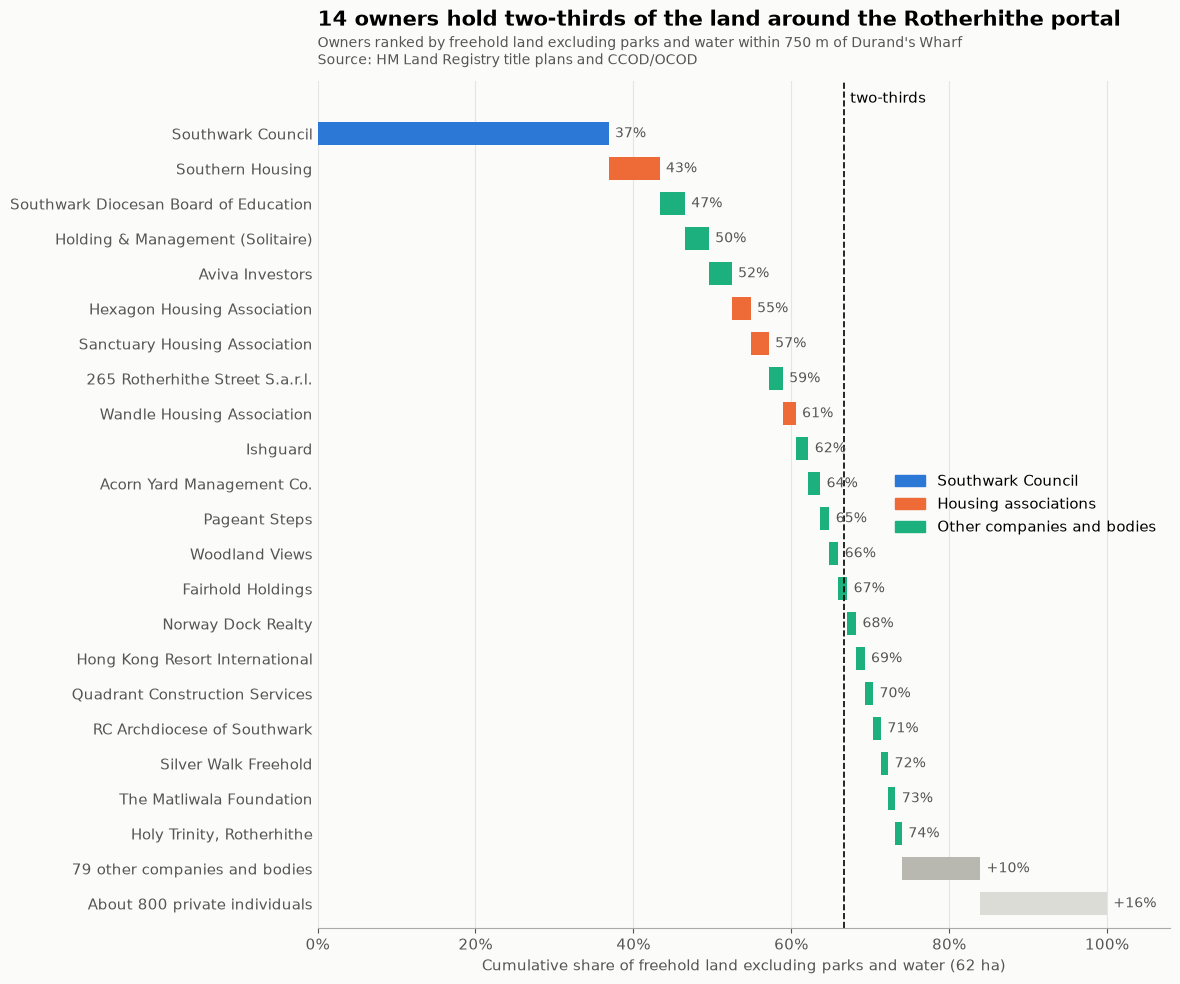

In [ ]:
TOP = 21
top = named.head(TOP)
rest = named.iloc[TOP:]
bars = pd.concat(
    [
        top[["name", "group", "share"]],
        pd.DataFrame(
            [
                {"name": f"{len(rest)} other companies and bodies", "group": "rest", "share": rest.share.sum()},
                {
                    "name": f"About {round(shares.titles.iloc[-1], -2):,.0f} private individuals",
                    "group": "private",
                    "share": shares.share.iloc[-1],
                },
            ]
        ),
    ],
    ignore_index=True,
)
bars["start"] = bars.share.cumsum() - bars.share

fig, ax = plt.subplots(figsize=(11, 11))
y = np.arange(len(bars))[::-1]
ax.barh(y, bars.share, left=bars.start, color=bars.group.map(COLOURS), height=0.65)
for yi, r in zip(y, bars.itertuples()):
    label = f"+{r.share:.0%}" if r.group in ("rest", "private") else f"{r.start + r.share:.0%}"
    ax.text(r.start + r.share + 0.008, yi, label, va="center", fontsize=10, color=COLOURS["text"])
ax.set_yticks(y, bars.name)
ax.tick_params(axis="y", length=0)
ax.axvline(2 / 3, color="black", ls="--", lw=1.2)
ax.text(2 / 3 + 0.008, y[0] + 1, "two-thirds", va="center")
ax.set_xlim(0, 1.08)
ax.set_ylim(-0.7, len(bars) + 0.5)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.spines["left"].set_visible(False)
ax.grid(axis="x", color="#e5e5e5")
ax.set_axisbelow(True)
total_ha = shares.net_m2.sum() / 1e4
ax.set_xlabel(f"Cumulative share of freehold land excluding parks and water ({total_ha:.0f} ha)")
ax.legend(
    handles=[plt.Rectangle((0, 0), 1, 1, color=COLOURS[k]) for k in ("southwark", "housing", "other")],
    labels=[GROUPS[k] for k in ("southwark", "housing", "other")],
    loc="center right",
)
ax.set_title(f"{n_two_thirds} owners hold two-thirds of the land around the Rotherhithe portal", pad=40)
ax.text(
    0,
    1.02,
    f"Owners ranked by freehold land excluding parks and water within {CATCHMENT_M} m of Durand's Wharf\n"
    "Source: HM Land Registry title plans and CCOD/OCOD",
    transform=ax.transAxes,
    color=COLOURS["text"],
    fontsize=10,
)
fig.savefig(FIGURES / "land_supermajority.png")

## Figure: the route

Tunnel 460 m; closest approach to the Jubilee line 42 m


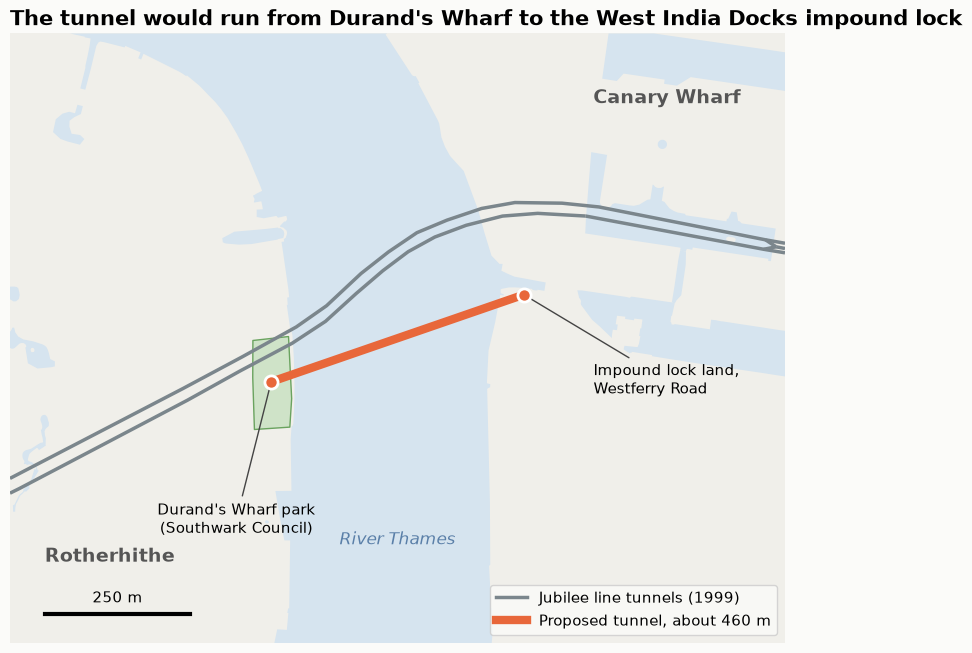

In [ ]:
line = tunnel_line()
x0, y0, x1, y1 = line.buffer(450).bounds
view = shapely.box(x0, y0, x1, y1)
cons = constraints(view.buffer(500))
water = cons[cons["class"] == "water"].clip(view)
durand = cons[(cons["class"] == "open_space") & cons.contains(Point(to_bng(SOUTH_PORTAL)))]
jubilee = jubilee_tunnels().clip(view)

fig, ax = plt.subplots(figsize=(10, 8))
gpd.GeoSeries([view], crs=BNG).plot(ax=ax, color=COLOURS["land"])
water.plot(ax=ax, color=COLOURS["water"])
durand.plot(ax=ax, color=COLOURS["park"], edgecolor="#6aa35f")
jubilee.plot(ax=ax, color=COLOURS["jubilee"], lw=2.5)
gpd.GeoSeries([line], crs=BNG).plot(ax=ax, color=COLOURS["tunnel"], lw=6, capstyle="round")
(sx, sy), (nx, ny) = line.coords
ax.scatter([sx, nx], [sy, ny], s=90, color=COLOURS["tunnel"], edgecolor="white", lw=2, zorder=5)
arrow = {"arrowstyle": "-", "color": "#444", "lw": 1}
ax.annotate(
    "Durand's Wharf park\n(Southwark Council)", (sx, sy), xytext=(sx - 60, sy - 260), ha="center", arrowprops=arrow
)
ax.annotate("Impound lock land,\nWestferry Road", (nx, ny), xytext=(nx + 120, ny - 170), ha="left", arrowprops=arrow)
ax.text(x0 + 60, y0 + 140, "Rotherhithe", fontsize=14, fontweight="bold", color=COLOURS["text"])
ax.text(x1 - 330, y1 - 120, "Canary Wharf", fontsize=14, fontweight="bold", color=COLOURS["text"])
ax.text((sx + nx) / 2, y0 + 170, "River Thames", fontsize=12, style="italic", color="#5a7fa8", ha="center")
ax.plot([x0 + 60, x0 + 310], [y0 + 50, y0 + 50], color="black", lw=3)
ax.text(x0 + 185, y0 + 70, "250 m", ha="center")
ax.legend(
    handles=[
        Line2D([0], [0], color=COLOURS["jubilee"], lw=2.5, label="Jubilee line tunnels (1999)"),
        Line2D(
            [0], [0], color=COLOURS["tunnel"], lw=6, label=f"Proposed tunnel, about {round(line.length, -1):.0f} m"
        ),
    ],
    loc="lower right",
    frameon=True,
)
ax.set_xlim(x0, x1)
ax.set_ylim(y0, y1)
ax.set_axis_off()
ax.set_title("The tunnel would run from Durand's Wharf to the West India Docks impound lock")
gap = line.distance(jubilee.union_all())
print(f"Tunnel {line.length:.0f} m; closest approach to the Jubilee line {gap:.0f} m")
fig.savefig(FIGURES / "route_map.png")

Saved for the crossing map, which can then be rebuilt without the Land Registry files.

In [ ]:
g.to_file(DERIVED / "catchment_plots.gpkg", driver="GPKG")